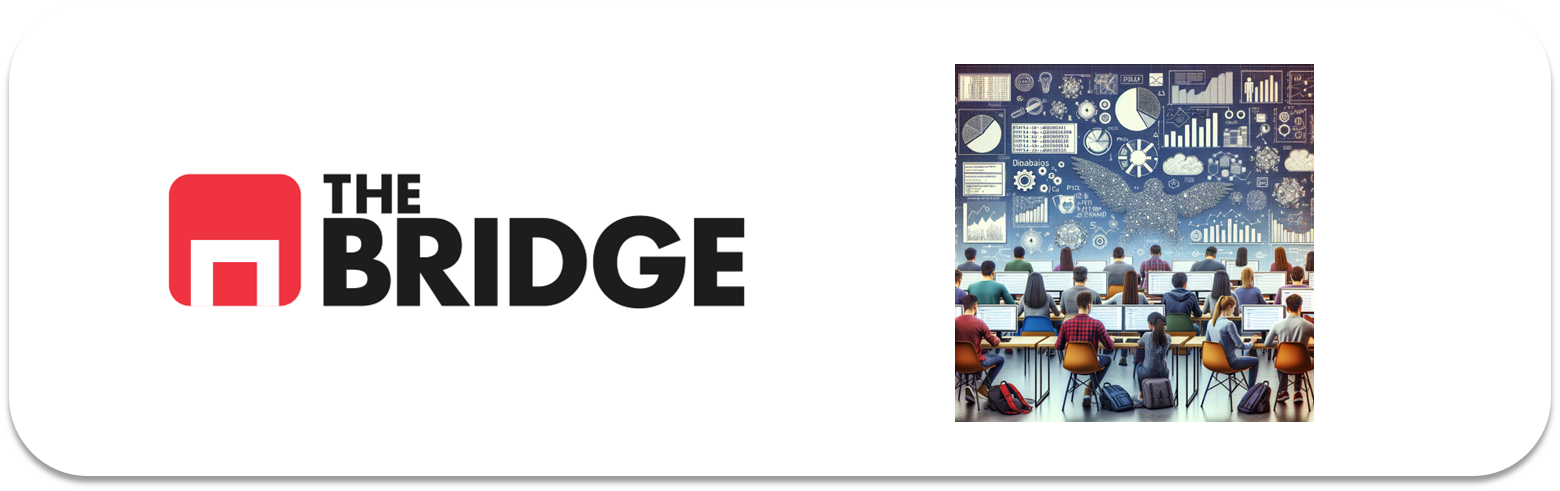

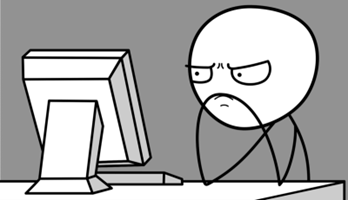

Para ejercitarte y afianzar lo aprendido sobre **Regularización**, completa los siguientes ejercicios. Recuerda que necesitarás datos que están en el directorio `data` de la raíz de la unidad (`../data`)
  
La solución a los mismos las tienes ya, intenta no mirarlos de primeras pero no dejes de hacerlo cuando hayas terminado por si te pudieran aportar.

### Ejercicio 0

Importa los paquetes y módulos que necesites a lo largo del notebook

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import metrics
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet

En estos ejercicios vamos a repasar la regularización sobre regresión lineal para predecir el precio de un coche. Como con las features originales la regresión lineal apenas sobreajusta, le daremos más complejidad con features polinómicas de grado 2; obtendremos primero un modelo de regresión lineal sobre ellas y luego los equivalentes con penalizaciones L2 (Ridge), L1 (Lasso) y con la combinación de ambas (ElasticNet)

### Ejercicio 1

Carga el dataset de partida ("../data/CarPrice_Assignment.csv") en el que tenemos diferentes modelos de coches con sus características y el precio de estos. Échale un vistazo

In [2]:
df = pd.read_csv("../data/CarPrice_Assignment.csv", dtype={"price":float})
df.head()

,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   car_ID            205 non-null    int64  
 1   symboling         205 non-null    int64  
 2   CarName           205 non-null    object 
 3   fueltype          205 non-null    object 
 4   aspiration        205 non-null    object 
 5   doornumber        205 non-null    object 
 6   carbody           205 non-null    object 
 7   drivewheel        205 non-null    object 
 8   enginelocation    205 non-null    object 
 9   wheelbase         205 non-null    float64
 10  carlength         205 non-null    float64
 11  carwidth          205 non-null    float64
 12  carheight         205 non-null    float64
 13  curbweight        205 non-null    int64  
 14  enginetype        205 non-null    object 
 15  cylindernumber    205 non-null    object 
 16  enginesize        205 non-null    int64  
 1

### Ejercicio 2

Identifica la variable target y asígnala a una variable de nombre `target`, luego elimina de forma permanente el campo "car_ID"

In [4]:
target = "price"

In [5]:
df.drop("car_ID", axis = 1, inplace = True)

### Ejercicio 3

Haz un split del dataset en train y test al 80/20 empleando la función de sklearn que ya conoces

In [6]:
train_set, test_set = train_test_split(df, test_size= 0.2, random_state= 42)

### Ejercicio 4

Aunque vamos a emplear todas las variables numéricas del dataset como predictores o features, obtén la correlación de todas ellas con el target y escoge los que creas que son tus tres mejores predictores. Crea una lista con los nombres de las variables numéricas y llámala `features_num`

In [7]:
corr = train_set.corr(numeric_only= True)
# Tomamos valor absoluto ANTES de ordenar: tan buena es una correlación fuerte positiva como negativa
# (perdemos el signo, que podríamos analizar después)
corr[target].abs().sort_values(ascending = False)

price               1.000000
enginesize          0.866433
curbweight          0.824212
horsepower          0.810986
carwidth            0.744310
highwaympg          0.713503
citympg             0.711245
carlength           0.652071
boreratio           0.546099
wheelbase           0.506118
peakrpm             0.070017
carheight           0.044458
compressionratio    0.035218
stroke              0.023941
symboling           0.005183
Name: price, dtype: float64

In [8]:
features_num = corr[target].index.to_list()
features_num.remove(target)
features_num

['symboling',
 'wheelbase',
 'carlength',
 'carwidth',
 'carheight',
 'curbweight',
 'enginesize',
 'boreratio',
 'stroke',
 'compressionratio',
 'horsepower',
 'peakrpm',
 'citympg',
 'highwaympg']

*Así de primeras parece que nos quedaríamos con el tamaño del motor (enginesize), el peso en vacío (curbweight) y la potencia en caballos (horsepower). Fíjate también en que citympg y highwaympg correlan fuerte (negativamente: más consumo, más precio) y aparecen arriba gracias al valor absoluto. Luego lo comprobaremos al pintar los pesos*

### Ejercicio 5

Completa el siguiente código que tiene como objetivo generar un modelo de regresión lineal utilizando las features polinómicas de grado 2 (cuadrados e interacciones) de todas las variables numéricas (salvo la target). Fíjate en que primero generamos las features polinómicas y después escalamos, siempre ajustando (`fit`) solo con train:

In [9]:
# Separación x e y
X_train = train_set.drop(columns= [target])
y_train = train_set[target]

X_test = test_set.drop(columns = [target])
y_test = test_set[target]

# Features polinómicas de grado 2
poly = PolynomialFeatures(degree= 2, include_bias= False)
X_train_poly = poly.fit_transform(X_train[features_num])
X_test_poly = poly.transform(X_test[features_num])

# Escalado
scaler = StandardScaler()
columnas = poly.get_feature_names_out() # nombres de las nuevas features, p.ej. "enginesize^2" o "horsepower citympg"
X_train = pd.DataFrame(scaler.fit_transform(X_train_poly), columns= columnas)
X_test = pd.DataFrame(scaler.transform(X_test_poly), columns= columnas)

lin_reg = LinearRegression()
lin_reg.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](119,)","[ -7139.17, 166680.44, 300864.64,...,-159699.92, 261617.89,-114431.78]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](119,)","['symboling','wheelbase','carlength',...,'citympg^2','citympg highwaympg', 'highwaympg^2']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.322e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,119
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,119


### Ejercicio 6

Obtén el MAE,RMSE y $R^2$ para las predicciones sobre train (X_train) y para las predicciones sobre test (X_test). ¿Podemos esperar una buena generalización?

*Para Train*

In [10]:
y_pred = lin_reg.predict(X_train)

argumentos = (y_train, y_pred)

print('MSE:', metrics.mean_squared_error(*argumentos))
print('RMSE:', np.sqrt(metrics.mean_squared_error(*argumentos)))
print('MAE:', metrics.mean_absolute_error(*argumentos))
print('MAPE:', metrics.mean_absolute_percentage_error(*argumentos))
print('R2:', lin_reg.score(X_train, y_train))

MSE: 501347.54546853935
RMSE: 708.0589985788891
MAE: 499.9172733643786
MAPE: 0.04669400928480615
R2: 0.9915934653662309


*Para Test*

In [11]:
y_pred = lin_reg.predict(X_test)

argumentos = (y_test, y_pred)

print('MSE:', metrics.mean_squared_error(*argumentos))
print('RMSE:', np.sqrt(metrics.mean_squared_error(*argumentos)))
print('MAE:', metrics.mean_absolute_error(*argumentos))
print('MAPE:', metrics.mean_absolute_percentage_error(*argumentos))
print('R2:', lin_reg.score(X_test, y_test))

MSE: 151861941.19369003
RMSE: 12323.227710047804
MAE: 6197.043924394656
MAPE: 0.599090993723648
R2: -0.9236661561131843


*Sobreajuste brutal: en train el modelo es casi perfecto ($R^2$ 0.99, MAPE del 5%), pero en test se hunde ($R^2$ negativo, -0.92, es decir, peor que predecir siempre la media; MAPE del 60%). Con 119 features y solo 164 filas el modelo ha memorizado el train, así que no podemos esperar ninguna generalización. Veamos qué consigue la regularización*

### Ejercicio 7
 
Vamos a regularizar, crea un regresor Ridge con alpha inicial a 10 y entrénalo con el X_train. Obtén MAE, RMSE y $R^2$ considerando las predicciones sobre el mismo X_train

In [12]:
ridge_reg = Ridge(alpha= 10)

ridge_reg.fit(X_train,y_train)

,"alpha alpha: float or array-like of shape (n_targets,), default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.See :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`for an illustration of the effect of alpha on the model coefficients.",10
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' t

In [13]:
y_pred = ridge_reg.predict(X_train)

argumentos = (y_train, y_pred)

print('MSE:', metrics.mean_squared_error(*argumentos))
print('RMSE:', np.sqrt(metrics.mean_squared_error(*argumentos)))
print('MAE:', metrics.mean_absolute_error(*argumentos))
print('MAPE:', metrics.mean_absolute_percentage_error(*argumentos))
print('R2:', ridge_reg.score(X_train, y_train))

MSE: 6396083.924310666
RMSE: 2529.048027284311
MAE: 1822.5960823308276
MAPE: 0.13774121876973386
R2: 0.892751243092333


### Ejercicio 8

Evalúalo contra el X_test y obtén MAE,RMSE y $R^2$. ¿Generaliza mejor que la regresión lineal sin regularizar?

In [14]:
y_pred = ridge_reg.predict(X_test)

argumentos = (y_test, y_pred)

print('MSE:', metrics.mean_squared_error(*argumentos))
print('RMSE:', np.sqrt(metrics.mean_squared_error(*argumentos)))
print('MAE:', metrics.mean_absolute_error(*argumentos))
print('MAPE:', metrics.mean_absolute_percentage_error(*argumentos))
print('R2:', ridge_reg.score(X_test, y_test))

MSE: 11769942.504122447
RMSE: 3430.734980164228
MAE: 2355.661417632497
MAPE: 0.19172759873207484
R2: 0.8509077397759539


*Enorme mejora: el $R^2$ de test pasa de -0.92 a 0.85 y el RMSE de 12323 a 3431. A cambio, el ajuste en train empeora ($R^2$ de 0.99 a 0.89), pero la diferencia entre train y test es ahora mucho menor: Ridge generaliza muchísimo mejor*

### Ejercicio 9
 
Ahora crea un regresor Lasso con alpha inicial a 125 (y `max_iter=10000`, para que el algoritmo tenga iteraciones suficientes para converger) y entrénalo con el X_train. Obtén MAE, RMSE y $R^2$ considerando las predicciones sobre el mismo X_train.

In [15]:
lasso_reg = Lasso(alpha= 125, max_iter= 10000)

lasso_reg.fit(X_train,y_train)

,"alpha alpha: float, default=1.0Constant that multiplies the L1 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Lasso` object is not advised.Instead, you should use the :class:`LinearRegression` object.",125
,"max_iter max_iter: int, default=1000The maximum number of iterations.",10000
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.",False
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary <warm_start>`.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'
Name,Type,Value


In [16]:
y_pred = lasso_reg.predict(X_train)

argumentos = (y_train, y_pred)

print('MSE:', metrics.mean_squared_error(*argumentos))
print('RMSE:', np.sqrt(metrics.mean_squared_error(*argumentos)))
print('MAE:', metrics.mean_absolute_error(*argumentos))
print('MAPE:', metrics.mean_absolute_percentage_error(*argumentos))
print('R2:', lasso_reg.score(X_train, y_train))

MSE: 7908969.077891139
RMSE: 2812.288939261245
MAE: 2024.2858050552495
MAPE: 0.15279064233369558
R2: 0.867383368939078


### Ejercicio 10

Evalúalo contra el X_test y obtén MAE,RMSE y $R^2$. ¿Generaliza mejor que los otros dos modelos?

In [17]:
y_pred = lasso_reg.predict(X_test)

argumentos = (y_test, y_pred)

print('MSE:', metrics.mean_squared_error(*argumentos))
print('RMSE:', np.sqrt(metrics.mean_squared_error(*argumentos)))
print('MAE:', metrics.mean_absolute_error(*argumentos))
print('MAPE:', metrics.mean_absolute_percentage_error(*argumentos))
print('R2:', lasso_reg.score(X_test, y_test))

MSE: 13494858.099152876
RMSE: 3673.534823457221
MAE: 2581.6415683813125
MAPE: 0.22238343377547728
R2: 0.8290578824237437


*También corrige el sobreajuste ($R^2$ de test 0.83), algo peor que Ridge con estos valores de alpha, pero con un modelo mucho más simple: como veremos en el EXTRA, solo usa 12 de las 119 features*

### Ejercicio 11

Repite los ejercicios 9 y 10 con un regresor ElasticNet con alpha 0.2, l1_ratio a 0.7 y `max_iter=50000`. ¿Es mejor generalizando que el resto?

In [18]:
elastic_reg = ElasticNet(alpha= 0.2, l1_ratio= 0.7, max_iter= 50000)

elastic_reg.fit(X_train,y_train)

,"alpha alpha: float, default=1.0Constant that multiplies the penalty terms. Defaults to 1.0.See the notes for the exact mathematical meaning of thisparameter. ``alpha = 0`` is equivalent to an ordinary least square,solved by the :class:`LinearRegression` object. For numericalreasons, using ``alpha = 0`` with the ``Lasso`` object is not advised.Given this, you should use the :class:`LinearRegression` object.",0.2
,"l1_ratio l1_ratio: float, default=0.5The ElasticNet mixing parameter, with ``0 <= l1_ratio <= 1``. For``l1_ratio = 0`` the penalty is an L2 penalty. ``For l1_ratio = 1`` itis an L1 penalty. For ``0 < l1_ratio < 1``, the penalty is acombination of L1 and L2.",0.7
,"max_iter max_iter: int, default=1000The maximum number of iterations.",50000
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If ``False``, thedata is assumed to be already centered.",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.Check :ref:`an example on how to use a precomputed Gram Matrix in ElasticNet<sphx_glr_auto_examples_linear_model_plot_elastic_net_precomputed_gram_matrix_with_weighted_samples.py>`for details.",False
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary <warm_start>`.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'


In [19]:
y_pred = elastic_reg.predict(X_train)

argumentos = (y_train, y_pred)

print('MSE:', metrics.mean_squared_error(*argumentos))
print('RMSE:', np.sqrt(metrics.mean_squared_error(*argumentos)))
print('MAE:', metrics.mean_absolute_error(*argumentos))
print('MAPE:', metrics.mean_absolute_percentage_error(*argumentos))
print('R2:', elastic_reg.score(X_train, y_train))

MSE: 6386260.585237558
RMSE: 2527.1051789028406
MAE: 1821.0690258490383
MAPE: 0.13764770108387303
R2: 0.8929159596465153


In [20]:
y_pred = elastic_reg.predict(X_test)

argumentos = (y_test, y_pred)

print('MSE:', metrics.mean_squared_error(*argumentos))
print('RMSE:', np.sqrt(metrics.mean_squared_error(*argumentos)))
print('MAE:', metrics.mean_absolute_error(*argumentos))
print('MAPE:', metrics.mean_absolute_percentage_error(*argumentos))
print('R2:', elastic_reg.score(X_test, y_test))

MSE: 11763175.955128245
RMSE: 3429.7486722977596
MAE: 2354.351391362119
MAPE: 0.19153787000204806
R2: 0.850993453030977


*Prácticamente empata con Ridge ($R^2$ de test 0.851 en ambos): las diferencias entre los modelos regularizados son pequeñas comparadas con la mejora frente a la regresión sin regularizar. Tendríamos que optimizar los hiperparámetros alpha y l1_ratio en este caso, y el alpha en las otras dos regularizaciones*

### Ejercicio 12

¿Qué podrías hacer para mejorar los regresores regularizados?

*Ajustar sus hiperparámetros: alpha en los tres modelos y además l1_ratio en ElasticNet. Para ello probaríamos diferentes rangos de valores y nos quedaríamos con los que diesen mejor métrica, pero **no midiendo contra el test** (eso sería hacer trampa: el test dejaría de ser un conjunto "no visto"), sino con validación cruzada sobre train, que veremos al hablar del ajuste (*tuning*) de hiperparámetros*

### EXTRA:

Utiliza la función siguiente para pintar la importancia de los coeficientes en cada uno de los cuatro modelos y observa el efecto de las penalizaciones de cada una de las regularizaciones:

In [21]:
def show_coefs(model, top=20, figsize=(10, 6)):
    """Pinta los `top` coeficientes de mayor valor absoluto (con 119 features no caben todos)"""
    df_coef = pd.DataFrame(model.coef_, index=model.feature_names_in_, columns=["coefs"])
    df_top = df_coef.loc[df_coef["coefs"].abs().sort_values(ascending=False).index[:top]]

    fig, ax = plt.subplots(1, 2, figsize=figsize)
    df_top.plot(kind="barh", ax=ax[0], legend=False)
    df_top.abs().sort_values(by="coefs").plot(kind="barh", ax=ax[1], legend=False)
    fig.suptitle(f"Coeficientes del modelo (los {top} mayores en valor absoluto)")

    fig.tight_layout()
    print("Coeficientes a cero:", (df_coef["coefs"] == 0).sum(), "de", len(df_coef))

    return df_top

*La función muestra dos gráficos de barras horizontales con los 20 coeficientes de mayor valor absoluto: el de la izquierda con valor y signo, el de la derecha solo con el valor. Además indica cuántos coeficientes son exactamente cero*

**Regresion_Lineal**

Coeficientes a cero: 0 de 119


,coefs
wheelbase carlength,-471247.143488
wheelbase carwidth,-442777.922886
wheelbase^2,410725.284571
highwaympg,401965.707646
citympg,-363104.090062
wheelbase curbweight,-349051.300367
compressionratio,-334294.194923
carwidth horsepower,-309870.230112
carlength,300864.642489
carlength highwaympg,-300022.070637


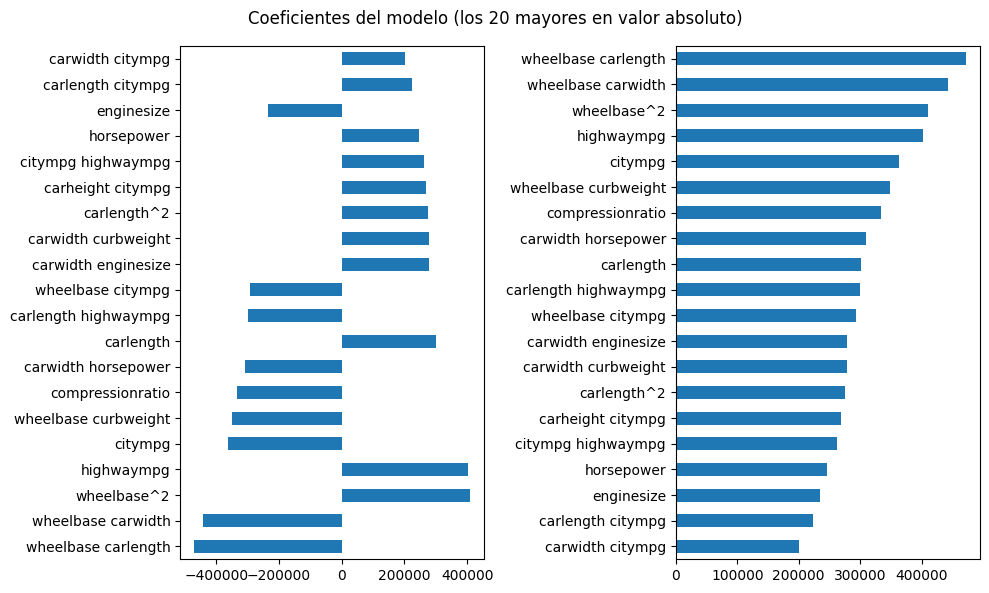

In [22]:
show_coefs(lin_reg)

**Ridge**

Coeficientes a cero: 0 de 119


,coefs
symboling horsepower,977.606858
carheight enginesize,955.851547
symboling peakrpm,808.757057
enginesize boreratio,762.243146
highwaympg^2,753.530557
boreratio citympg,-707.519713
symboling stroke,-703.052517
peakrpm^2,670.938990
wheelbase enginesize,668.829037
horsepower citympg,-646.267929


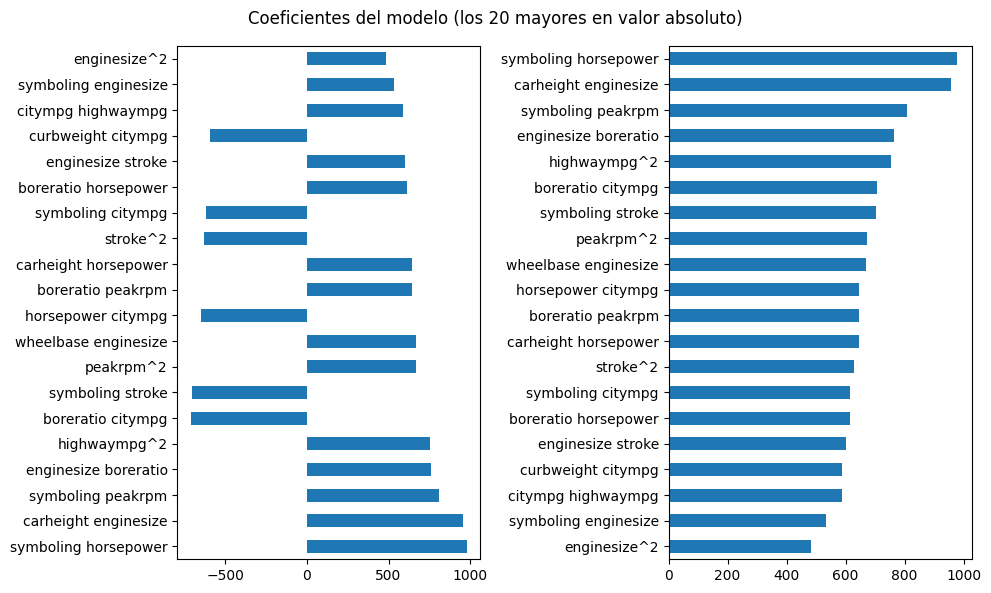

In [23]:
show_coefs(ridge_reg)

*Observa la escala: los coeficientes de la regresión lineal sin regularizar son de cientos de miles, y features muy parecidas tienen coeficientes enormes de signo contrario (p.ej. `wheelbase carlength` y `wheelbase^2`) que se compensan entre sí para ajustar el train. Los de Ridge no llegan a mil: Ridge suaviza, ningún coeficiente es cero pero ninguno se dispara*

**Lasso**

Coeficientes a cero: 107 de 119


,coefs
carheight enginesize,3529.995366
boreratio citympg,-1139.380554
compressionratio peakrpm,989.792952
enginesize^2,943.708753
carwidth^2,921.029589
horsepower peakrpm,829.680316
stroke^2,-716.919554
boreratio peakrpm,496.906664
symboling horsepower,362.848058
curbweight^2,204.985760


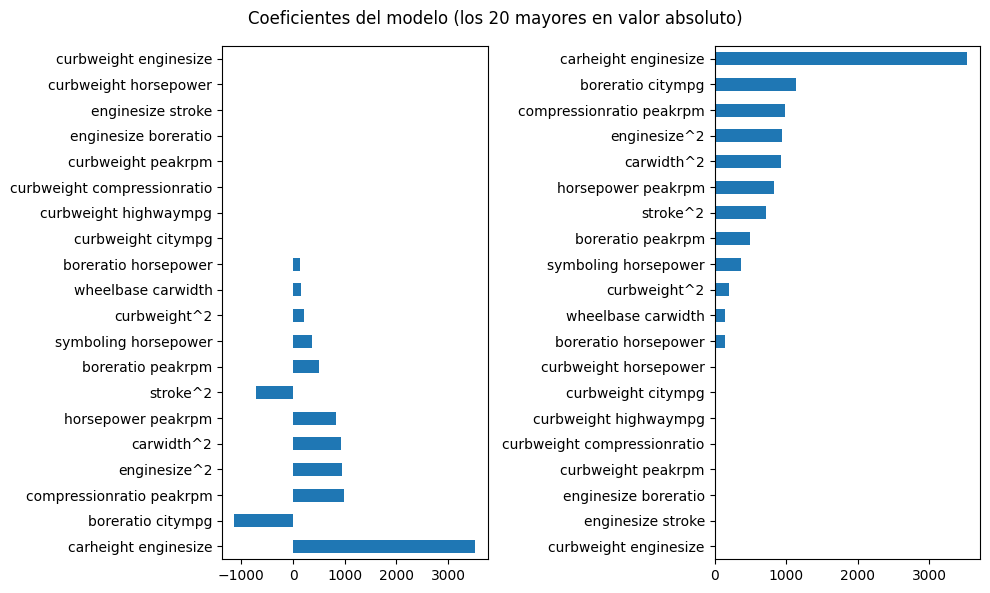

In [24]:
show_coefs(lasso_reg)

*En cambio, Lasso no solo suaviza, también selecciona: ha dejado a cero 107 de los 119 coeficientes y se queda con 12 features, con `carheight enginesize` (tamaño del motor combinado con la altura del coche) como la más importante. El efecto de selección de features se ve claramente*

**ElasticNet**

Coeficientes a cero: 1 de 119


,coefs
symboling horsepower,982.772464
carheight enginesize,963.064913
symboling peakrpm,816.652782
enginesize boreratio,767.077805
highwaympg^2,759.132387
boreratio citympg,-713.783378
symboling stroke,-709.739701
peakrpm^2,676.953822
wheelbase enginesize,672.248475
boreratio peakrpm,649.767158


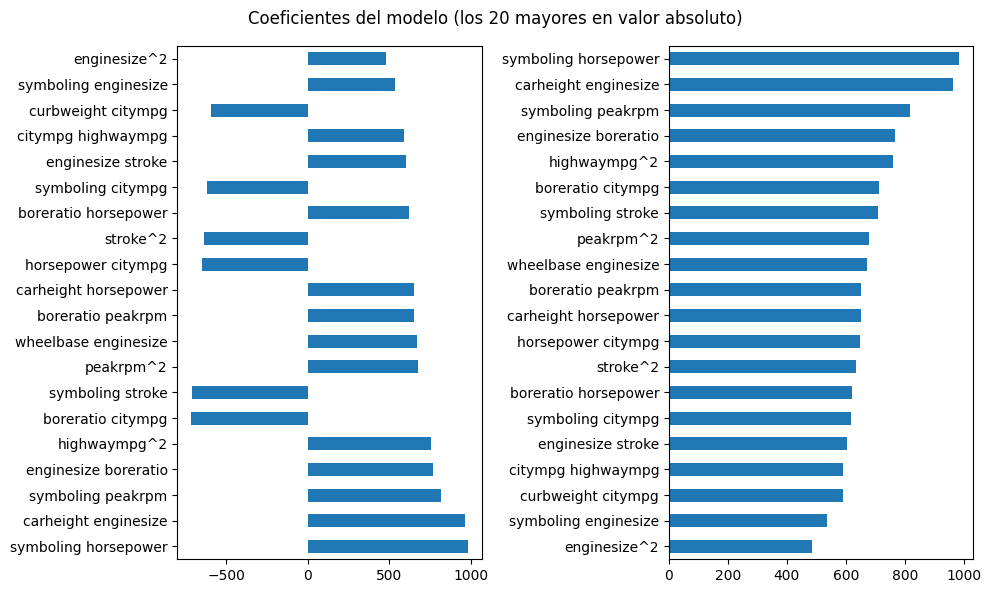

In [25]:
show_coefs(elastic_reg)

*Con alpha=0.2 la penalización es pequeña y el resultado es muy parecido al de Ridge: a pesar del alto peso de L1 (l1_ratio=0.7) solo ha llevado un coeficiente a cero, ha suavizado más que seleccionado. Para ver selección habría que subir alpha*